# Modern Cinema Collaboration Network (2018–2026)
### Social Network Analysis — Topology, Small-World Dynamics, and Community Partitioning

This interactive Google Colab notebook implements the complete data extraction, network construction, topological characterization, and visualization pipeline for the Modern Cinema Collaboration Network project.

**Project Steps Covered:**
* **Step 1:** Web data extraction, bipartite-to-unipartite projection, tie weighting, and GraphML export.
* **Step 2:** Empirical network characterization (diameter, path length, clustering, centralities, and Louvain community detection).
* **Step 3:** Network visualization using a force-directed layout with centrality sizing and community coloring.


### 1. Setup & Dependencies

In [1]:
# Install required dependencies if running in a fresh Colab environment
!pip install -q networkx matplotlib scipy

import urllib.request
import json
import itertools
import time
import os
import networkx as nx
import networkx.algorithms.community as nx_comm
import matplotlib.pyplot as plt

print(f"NetworkX Version: {nx.__version__}")


error: externally-managed-environment

× This environment is externally managed
╰─> This Python installation is managed by uv and should not be modified.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


NetworkX Version: 3.6.1


### 2. Step 1: Web Data Ingestion & Bipartite Projection
We extract metadata across feature films released between 2018 and 2026. The bipartite affiliation structure (Movies $\leftrightarrow$ Actors) is projected into an undirected, weighted unipartite actor network $G = (V, E, W)$, retaining the top 4 billed principal actors per film to prevent combinatorial clique expansion. Tie strength $w(u, v) \ge 1$ represents co-starring frequency.


In [2]:
# 1. Fetch or load the dataset
cache_file = "movies_cache.json"

if os.path.exists(cache_file):
    print("Loading cached movie dataset...")
    with open(cache_file, "r", encoding="utf-8") as f:
        data = json.load(f)
else:
    url = "https://raw.githubusercontent.com/prust/wikipedia-movie-data/master/movies.json"
    print(f"Fetching dataset from {url}...")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=15) as resp:
        data = json.loads(resp.read().decode("utf-8"))
    with open(cache_file, "w", encoding="utf-8") as f:
        json.dump(data, f)
    print(f"Cached {len(data)} movies locally.")

# Filter for modern cinema feature films (2018 onwards)
modern_movies = [m for m in data if m.get("year", 0) >= 2018 and len(m.get("cast", [])) >= 2]
print(f"Extracted {len(modern_movies)} modern feature films (2018–2026).")

# 2. Construct the unipartite actor collaboration graph
G = nx.Graph()
max_billing = 4

for m in modern_movies:
    cast = [actor.strip() for actor in m.get("cast", [])[:max_billing] if actor.strip()]
    title = m.get("title", "Unknown")
    year = m.get("year", 0)
    genres = ", ".join(m.get("genres", []))
    primary_genre = genres.split(", ")[0] if genres else "Drama"

    # Add or update vertices
    for actor in cast:
        if not G.has_node(actor):
            G.add_node(actor, film_count=1, sample_films=title, primary_genre=primary_genre)
        else:
            G.nodes[actor]["film_count"] += 1
            sample = G.nodes[actor]["sample_films"].split("; ")
            if len(sample) < 3 and title not in sample:
                G.nodes[actor]["sample_films"] += "; " + title

    # Add or update weighted edges (Granovetter's tie strength)
    for u, v in itertools.combinations(cast, 2):
        if G.has_edge(u, v):
            G[u][v]["weight"] += 1
            shared = G[u][v]["movies"].split("; ")
            if title not in shared:
                G[u][v]["movies"] += "; " + title
        else:
            G.add_edge(u, v, weight=1, movies=title)

print(f"Collaboration Graph G constructed: {G.number_of_nodes()} vertices, {G.number_of_edges()} edges.")


Loading cached movie dataset...
Extracted 1634 modern feature films (2018–2026).
Collaboration Graph G constructed: 3296 vertices, 8602 edges.


### 3. Step 1 Deliverable: GraphML Export
We serialize the collaboration network to a standardized GraphML file containing all node attributes (film counts, primary genres) and edge attributes (collaboration weights, shared titles).


In [3]:
# Export graph to GraphML format
graphml_path = "cinema_network.graphml"
nx.write_graphml(G, graphml_path)
print(f"Network successfully exported to GraphML format: {graphml_path}")
print(f"File size: {os.path.getsize(graphml_path) / (1024*1024):.2f} MB")


Network successfully exported to GraphML format: cinema_network.graphml
File size: 1.69 MB


### 4. Step 2: Empirical Network Characterization
We compute baseline global graph metrics, isolate the Giant Connected Component (GCC), and test for small-world properties (high clustering alongside low diameter and short average path length).


In [4]:
# Global Graph Properties
n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()
density = nx.density(G)
avg_clustering = nx.average_clustering(G)

# Component Analysis
ccs = sorted(nx.connected_components(G), key=len, reverse=True)
n_ccs = len(ccs)
gcc = G.subgraph(ccs[0]).copy()
gcc_nodes = gcc.number_of_nodes()
gcc_edges = gcc.number_of_edges()
gcc_pct = (gcc_nodes / n_nodes) * 100

# Diameter and Path Length on GCC
t0 = time.time()
diameter = nx.diameter(gcc)
avg_path = nx.average_shortest_path_length(gcc)
calc_time = time.time() - t0

print("="*65)
print("EMPIRICAL NETWORK CHARACTERIZATION (STEP 2 METRICS)")
print("="*65)
print(f"Total Vertices (|V|)          : {n_nodes}")
print(f"Total Edges (|E|)             : {n_edges}")
print(f"Connected Components          : {n_ccs}")
print(f"Giant Connected Component (GCC): {gcc_nodes} vertices ({gcc_pct:.2f}% of network), {gcc_edges} edges")
print(f"Network Density               : {density:.6f} (GCC Density: {nx.density(gcc):.6f})")
print(f"Average Clustering (C)        : {avg_clustering:.4f} (GCC: {nx.average_clustering(gcc):.4f})")
print(f"GCC Diameter (D)              : {diameter} hops (computed in {calc_time:.2f}s)")
print(f"GCC Average Path Length (L)   : {avg_path:.3f} hops (Bacon Number)")


EMPIRICAL NETWORK CHARACTERIZATION (STEP 2 METRICS)
Total Vertices (|V|)          : 3296
Total Edges (|E|)             : 8602
Connected Components          : 143
Giant Connected Component (GCC): 2774 vertices (84.16% of network), 7885 edges
Network Density               : 0.001584 (GCC Density: 0.002050)
Average Clustering (C)        : 0.7235 (GCC: 0.6887)
GCC Diameter (D)              : 13 hops (computed in 3.13s)
GCC Average Path Length (L)   : 5.096 hops (Bacon Number)


### 5. Step 2: Centrality Rankings & Louvain Community Modularity
We evaluate vertex centrality distributions:
1. **Degree Centrality:** Prolific ensemble actors.
2. **Betweenness Centrality ($C_B$):** Structural bridge actors connecting disparate production circuits.
3. **Local Clustering ($C_i$):** Tight, recurring ensemble cliques.
4. **Louvain Modularity ($Q$):** Modularity optimization across the GCC.


In [5]:
# 1. Degree Centrality (Top-5)
deg_sorted = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:5]
print("--- TOP 5 VERTICES BY DEGREE (TOTAL CO-STARS) ---")
for rank, (act, deg) in enumerate(deg_sorted, 1):
    print(f"{rank}. {act}: {deg} co-stars across {G.nodes[act]['film_count']} films")

# 2. Freeman Betweenness Centrality on GCC (Top-5)
print("\n--- TOP 5 VERTICES BY BETWEENNESS CENTRALITY (GCC BRIDGES) ---")
bc = nx.betweenness_centrality(gcc)
bc_sorted = sorted(bc.items(), key=lambda x: x[1], reverse=True)[:5]
for rank, (act, val) in enumerate(bc_sorted, 1):
    print(f"{rank}. {act}: C_B = {val:.5f} (Degree: {G.degree(act)})")

# 3. Local Clustering Coefficients (Degree >= 5 to isolate cliques)
print("\n--- TOP 5 VERTICES BY CLUSTERING COEFFICIENT (DEGREE >= 5) ---")
clust = nx.clustering(G)
clust_sorted = sorted([(act, c, G.degree(act)) for act, c in clust.items() if G.degree(act) >= 5],
                      key=lambda x: (x[1], x[2]), reverse=True)[:5]
for rank, (act, c, deg) in enumerate(clust_sorted, 1):
    print(f"{rank}. {act}: C_i = {c:.4f} (Degree: {deg})")

# 4. Louvain Community Detection
comms = nx_comm.louvain_communities(gcc, seed=42)
mod_q = nx_comm.modularity(gcc, comms)
print(f"\n--- LOUVAIN COMMUNITY PARTITION ON GCC ---")
print(f"Detected Communities: {len(comms)}")
print(f"Modularity Score Q   : {mod_q:.4f}")


--- TOP 5 VERTICES BY DEGREE (TOTAL CO-STARS) ---
1. Bruce Willis: 45 co-stars across 29 films
2. Frank Grillo: 37 co-stars across 14 films
3. Lil Rel Howery: 34 co-stars across 12 films
4. Margot Robbie: 32 co-stars across 11 films
5. Tiffany Haddish: 32 co-stars across 11 films

--- TOP 5 VERTICES BY BETWEENNESS CENTRALITY (GCC BRIDGES) ---


1. Bruce Willis: C_B = 0.04464 (Degree: 45)
2. Frank Grillo: C_B = 0.03760 (Degree: 37)
3. Lil Rel Howery: C_B = 0.02942 (Degree: 34)
4. Tiffany Haddish: C_B = 0.02760 (Degree: 32)
5. Ryan Reynolds: C_B = 0.02724 (Degree: 26)

--- TOP 5 VERTICES BY CLUSTERING COEFFICIENT (DEGREE >= 5) ---
1. Spencer Locke: C_i = 0.6000 (Degree: 5)
2. Danai Gurira: C_i = 0.6000 (Degree: 5)
3. Michael Greyeyes: C_i = 0.6000 (Degree: 5)
4. Chaske Spencer: C_i = 0.6000 (Degree: 5)
5. Dan Fogler: C_i = 0.6000 (Degree: 5)

--- LOUVAIN COMMUNITY PARTITION ON GCC ---
Detected Communities: 33
Modularity Score Q   : 0.6561


### 6. Step 3: Network Visualization (Fruchterman-Reingold Spring Layout)
We isolate the top 250 vertices by degree within the GCC to prevent graph density occlusion while preserving macro-topological structure.
* **Vertex Size:** Scaled proportionally to Freeman betweenness centrality ($C_B$), highlighting structural bridge actors.
* **Vertex Color:** Mapped to Louvain community partitions ($Q = 0.6561$).
* **Edge Transparency:** Highlights intra-community clusters vs. cross-community bridges.


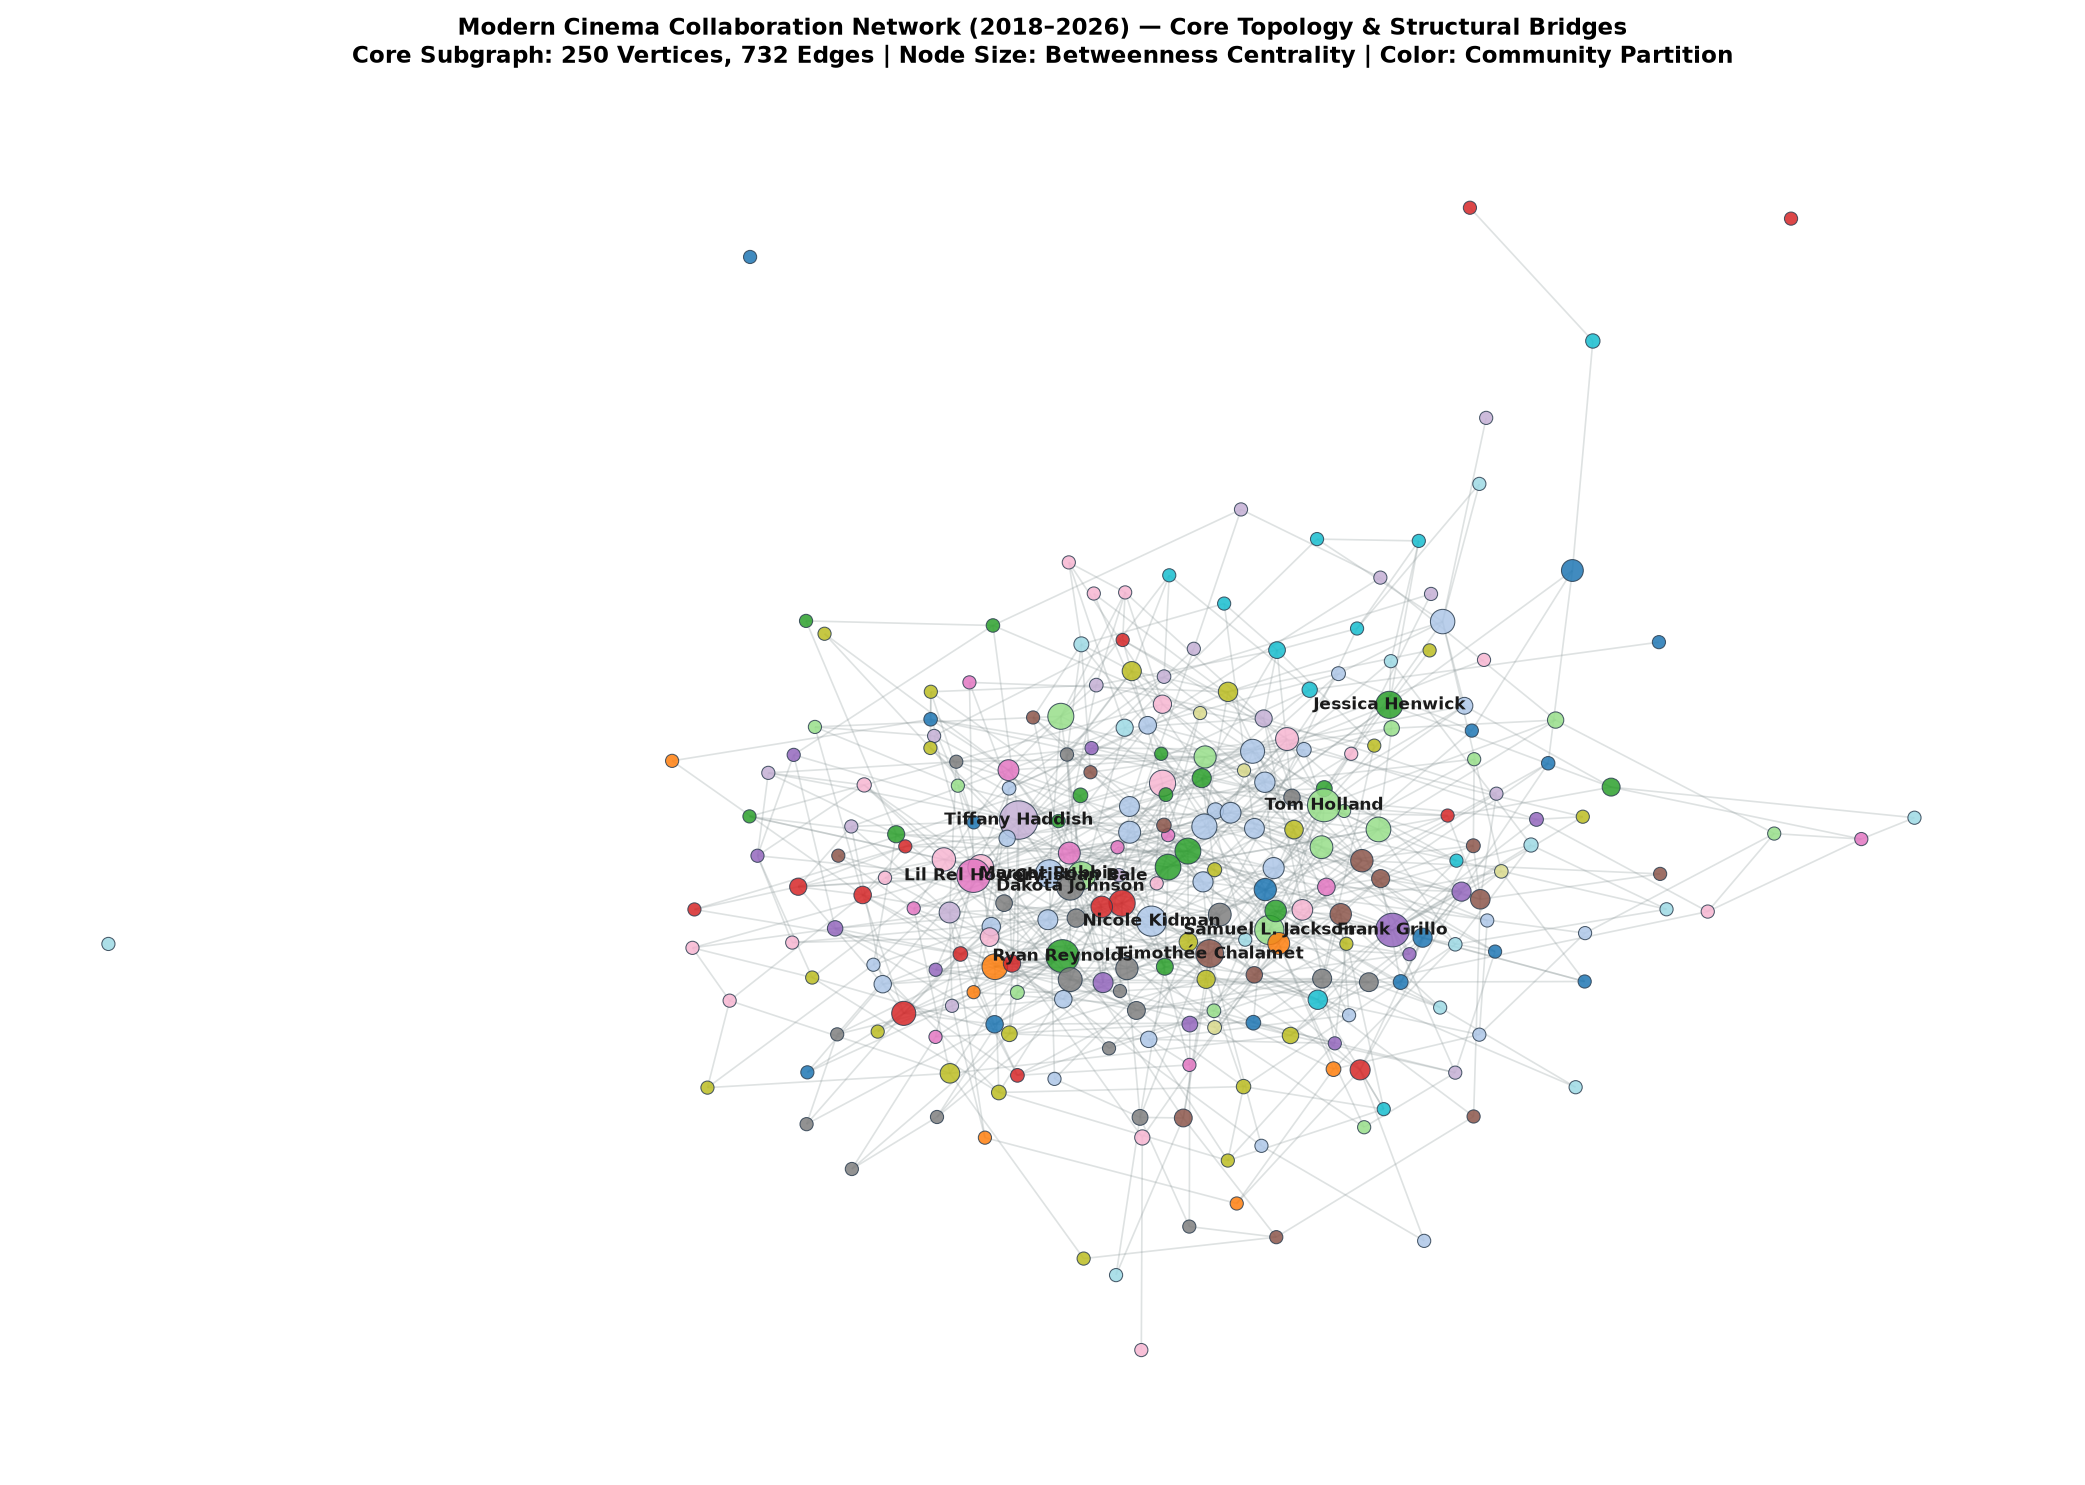

In [6]:
# Extract core subnetwork of top 250 vertices by degree
core_nodes = [node for node, deg in sorted(gcc.degree(), key=lambda x: x[1], reverse=True)[:250]]
core_subgraph = gcc.subgraph(core_nodes).copy()

# Map node to community ID
node_to_comm = {}
for comm_id, c in enumerate(comms):
    for node in c:
        node_to_comm[node] = comm_id

# Compute betweenness on core subgraph for node sizing
core_bc = nx.betweenness_centrality(core_subgraph)
node_sizes = [max(40, core_bc[n] * 6000) for n in core_subgraph.nodes()]
node_colors = [node_to_comm.get(n, 0) % 16 for n in core_subgraph.nodes()]

plt.figure(figsize=(14, 10), dpi=150)
pos = nx.spring_layout(core_subgraph, seed=42, k=0.18, iterations=50)

# Draw edges with subtle alpha transparency
nx.draw_networkx_edges(core_subgraph, pos, alpha=0.25, edge_color="#7f8c8d", width=0.8)

# Draw nodes sized by betweenness and colored by community
nx.draw_networkx_nodes(
    core_subgraph,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.85,
    edgecolors="#2c3e50",
    linewidths=0.5
)

# Label top 12 bridge actors
top_labeled = sorted(core_bc.items(), key=lambda x: x[1], reverse=True)[:12]
labels = {n: n for n, _ in top_labeled}
nx.draw_networkx_labels(core_subgraph, pos, labels=labels, font_size=8, font_weight="bold", font_color="#1a1a1a")

plt.title(
    "Modern Cinema Collaboration Network (2018–2026) — Core Topology & Structural Bridges\n"
    f"Core Subgraph: {core_subgraph.number_of_nodes()} Vertices, {core_subgraph.number_of_edges()} Edges | Node Size: Betweenness Centrality | Color: Community Partition",
    fontsize=11, fontweight="bold", pad=12
)
plt.axis("off")
plt.tight_layout()
plt.show()
